# Track 2: Quantum Optimization - Portfolio Selection

**Team:** Intellects
**Level:** Advanced

This notebook contains the complete quantum optimization pipeline for solving a budget-constrained portfolio selection problem using QAOA, custom constraint-preserving XY-Mixers, and hardware-aware error suppression.

In [1]:
!pip install qiskit qiskit_aer qiskit_ibm_runtime qiskit-optimization qiskit-finance matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 12.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 10.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.2/51.2 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 🟢 Beginner Level: Six Stocks with Standard QAOA

We are tasked with selecting exactly $K=3$ stocks out of $n=6$ to maximize expected returns ($\mu$) while minimizing covariance risk ($\Sigma$). Since quantum systems do not natively respect hard constraints, we formulate the objective as a Quadratic Unconstrained Binary Optimization (QUBO) problem by adding a penalty weight $\lambda$:

$$C(x)=q x^T \Sigma x-\mu^T x+\lambda(\sum_{i}x_i-K)^2$$

Below, we establish the classical brute-force baseline, translate the QUBO to an Ising Hamiltonian, and sweep both the QAOA depth ($p$) and penalty strength ($\lambda$) to evaluate sample quality.

In [2]:
import numpy as np

# From the Track 2 README
rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5               # 6 stocks, pick exactly 3, risk aversion
mu = rng.uniform(0.05, 0.25, n)   # expected returns
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T                   # covariance (risk)

In [3]:
import itertools

best_cost = float('inf')
worst_cost = float('-inf')
best_portfolio = None

# The cost function from the README: C(x) = q * (x^T * sigma * x) - mu^T * x
# Note: For brute force, we only calculate cost for valid portfolios (sum == K) to find the true minimum.

for bits in itertools.product([0, 1], repeat=n):
    x = np.array(bits)

    # Calculate raw cost (Risk - Return)
    cost = q * (x.T @ sigma @ x) - (mu.T @ x)

    # Track max cost across ALL 64 combinations for the approximation ratio formula
    if cost > worst_cost:
        worst_cost = cost

    # Track min cost ONLY for valid portfolios (budget K=3)
    if sum(x) == K:
        if cost < best_cost:
            best_cost = cost
            best_portfolio = x

print(f"True Best Portfolio: {best_portfolio}")
print(f"True Minimum Cost (C_min): {best_cost}")
print(f"Absolute Maximum Cost (C_max): {worst_cost}")

True Best Portfolio: [0 1 1 0 0 1]
True Minimum Cost (C_min): -0.5030146902647753
Absolute Maximum Cost (C_max): 0.0


In [4]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import LinearEqualityToPenalty

qp = QuadraticProgram("Portfolio_Optimization")

# Create binary variables for our 6 stocks
for i in range(n):
    qp.binary_var(name=f"x_{i}")

# Define the objective: Minimize (Risk - Return)
# qp.minimize(linear=-mu, quadratic=q * sigma)
linear_terms = {f"x_{i}": -mu[i] for i in range(n)}
quadratic_terms = {(f"x_{i}", f"x_{j}"): q * sigma[i,j] for i in range(n) for j in range(n)}
qp.minimize(linear=linear_terms, quadratic=quadratic_terms)

# Add the budget constraint: sum of x_i == K
qp.linear_constraint(linear={f"x_{i}": 1 for i in range(n)}, sense="==", rhs=K, name="budget")

# Convert the hard constraint into a math penalty (lambda)
# Let's start with lambda = 2.0
penalty_converter = LinearEqualityToPenalty(penalty=2.0)
qp_penalized = penalty_converter.convert(qp)

# Convert the math formula into Quantum Pauli Z operators
qubit_op, offset = qp_penalized.to_ising()
print("Hamiltonian created!")

Hamiltonian created!


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Depth p=1 | Expected Cost: 0.7735 | Approx Ratio (r): -1.5377
Depth p=2 | Expected Cost: 0.5247 | Approx Ratio (r): -1.0430
Depth p=3 | Expected Cost: -0.1616 | Approx Ratio (r): 0.3213
Depth p=4 | Expected Cost: 0.2988 | Approx Ratio (r): -0.5940

Top 5 sampled portfolios at p=4:
Portfolio: 011001 | Count:  196 | Valid Budget: True
Portfolio: 010101 | Count:  194 | Valid Budget: True
Portfolio: 110001 | Count:  183 | Valid Budget: True
Portfolio: 010011 | Count:  181 | Valid Budget: True
Portfolio: 101001 | Count:  176 | Valid Budget: True


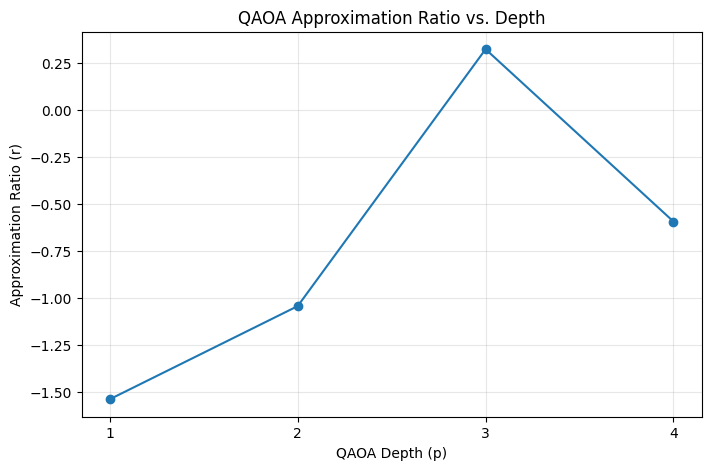

In [5]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize
import matplotlib.pyplot as plt

estimator = StatevectorEstimator()
sampler = StatevectorSampler()

approximation_ratios = []
depths = [1, 2, 3, 4]

for p in depths:
    # 1. Build the QAOA circuit without measurements for the Estimator
    ansatz = QAOAAnsatz(cost_operator=qubit_op, reps=p)

    # 2. Define the objective function for the classical optimizer
    def objective_function(params):
        pub = (ansatz, qubit_op, params)
        # Evaluate the expected energy of the cost Hamiltonian
        energy = estimator.run([pub]).result()[0].data.evs
        return float(energy)

    # 3. Optimize the parameters (beta and gamma)
    np.random.seed(42)
    initial_params = np.random.uniform(0, np.pi, ansatz.num_parameters)

    result = minimize(
        objective_function,
        initial_params,
        method="COBYLA",
        options={"maxiter": 200}
    )

    # 4. Calculate the expected classical cost <C>
    # qp.to_ising() returns an operator and a scalar offset.
    # True classical cost = quantum expectation value + offset
    expected_cost = result.fun + offset

    # 5. Calculate Approximation Ratio (r) as defined in the challenge prompt
    r = (worst_cost - expected_cost) / (worst_cost - best_cost)
    approximation_ratios.append(r)

    print(f"Depth p={p} | Expected Cost: {expected_cost:.4f} | Approx Ratio (r): {r:.4f}")

    # 6. Sample the best bitstrings at depth p=4
    if p == 4:
        ansatz_meas = ansatz.copy()
        ansatz_meas.measure_all()
        best_circuit = ansatz_meas.assign_parameters(result.x)

        # Run 4096 shots to get the probability distribution
        samples = sampler.run([best_circuit], shots=4096).result()[0].data.meas.get_counts()

        # Sort and print the top 5 most frequent portfolios
        sorted_samples = sorted(samples.items(), key=lambda x: x[1], reverse=True)
        print("\nTop 5 sampled portfolios at p=4:")
        for bitstring, count in sorted_samples[:5]:
            # Reverse bitstring because Qiskit uses little-endian ordering (rightmost is index 0)
            actual_portfolio = bitstring[::-1]
            is_valid = sum(int(b) for b in actual_portfolio) == K
            print(f"Portfolio: {actual_portfolio} | Count: {count:4d} | Valid Budget: {is_valid}")

# 7. Plot the Approximation Ratio vs Depth
plt.figure(figsize=(8, 5))
plt.plot(depths, approximation_ratios, marker='o', linestyle='-', color='#1f77b4')
plt.xlabel("QAOA Depth (p)")
plt.ylabel("Approximation Ratio (r)")
plt.title("QAOA Approximation Ratio vs. Depth")
plt.xticks(depths)
plt.grid(True, alpha=0.3)
plt.show()

<>:72: SyntaxWarning: invalid escape sequence '\l'
<>:72: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_2431/2992867642.py:72: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('Penalty Strength ($\lambda$)')


Starting lambda sweep. This will take a minute or two...
Lambda: 0.10 | Valid %:  48.0% | Best Portfolio %:   2.9%
Lambda: 0.42 | Valid %:  64.7% | Best Portfolio %:   2.1%
Lambda: 0.74 | Valid %:  60.4% | Best Portfolio %:   2.6%
Lambda: 1.07 | Valid %:  60.1% | Best Portfolio %:   4.4%
Lambda: 1.39 | Valid %:  67.3% | Best Portfolio %:   3.3%
Lambda: 1.71 | Valid %:  64.5% | Best Portfolio %:   2.5%
Lambda: 2.03 | Valid %:  64.2% | Best Portfolio %:   2.3%
Lambda: 2.36 | Valid %:  77.2% | Best Portfolio %:   3.7%
Lambda: 2.68 | Valid %:  55.4% | Best Portfolio %:   2.9%
Lambda: 3.00 | Valid %:  80.0% | Best Portfolio %:   3.4%


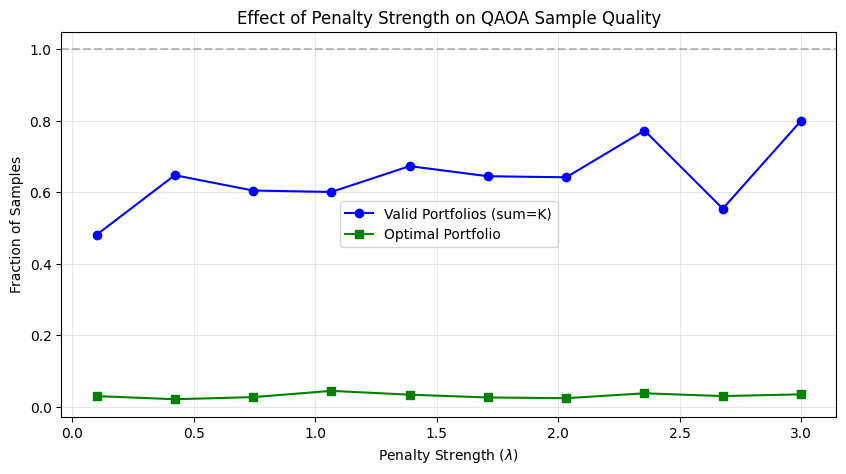

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit.circuit.library import QAOAAnsatz
from qiskit_optimization.converters import LinearEqualityToPenalty
from scipy.optimize import minimize

# Convert our true best classical portfolio array into a string for easy checking
best_portfolio_str = "".join(str(int(b)) for b in best_portfolio)

lambda_values = np.linspace(0.1, 3.0, 10)
valid_fractions = []
best_portfolio_fractions = []

print("Starting lambda sweep. This will take a minute or two...")

for lam in lambda_values:
    # 1. Apply the new lambda penalty to our base QuadraticProgram
    penalty_converter = LinearEqualityToPenalty(penalty=lam)
    qp_penalized = penalty_converter.convert(qp)

    # 2. Convert to quantum operator
    qubit_op, offset = qp_penalized.to_ising()

    # 3. Build QAOA circuit (using p=2 for a good balance of speed and accuracy)
    ansatz = QAOAAnsatz(cost_operator=qubit_op, reps=2)

    def cost_fn(params):
        pub = (ansatz, qubit_op, params)
        return float(estimator.run([pub]).result()[0].data.evs)

    # 4. Optimize
    np.random.seed(2026)
    init_params = np.random.uniform(0, np.pi, ansatz.num_parameters)
    res = minimize(cost_fn, init_params, method="COBYLA", options={"maxiter": 100})

    # 5. Sample the results (1024 shots)
    ansatz_meas = ansatz.copy()
    ansatz_meas.measure_all()
    bound_circ = ansatz_meas.assign_parameters(res.x)

    samples = sampler.run([bound_circ], shots=1024).result()[0].data.meas.get_counts()

    # 6. Analyze samples
    valid_count = 0
    best_count = 0

    for bitstring, count in samples.items():
        actual_port = bitstring[::-1]  # reverse little-endian

        # Check if it obeys the K=3 budget
        if sum(int(b) for b in actual_port) == K:
            valid_count += count

        # Check if it is the absolute best portfolio
        if actual_port == best_portfolio_str:
            best_count += count

    valid_frac = valid_count / 1024
    best_frac = best_count / 1024

    valid_fractions.append(valid_frac)
    best_portfolio_fractions.append(best_frac)

    print(f"Lambda: {lam:.2f} | Valid %: {valid_frac*100:>5.1f}% | Best Portfolio %: {best_frac*100:>5.1f}%")

# 7. Plot the results
plt.figure(figsize=(10, 5))
plt.plot(lambda_values, valid_fractions, marker='o', label='Valid Portfolios (sum=K)', color='blue')
plt.plot(lambda_values, best_portfolio_fractions, marker='s', label='Optimal Portfolio', color='green')
plt.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel('Penalty Strength ($\lambda$)')
plt.ylabel('Fraction of Samples')
plt.title('Effect of Penalty Strength on QAOA Sample Quality')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 🟠 Intermediate Level: Constraint-Preserving XY-Mixer ($n=12$)

Standard QAOA relies on mathematical penalties, meaning the quantum computer wastes capacity exploring invalid portfolios that break the budget. To solve a larger $n=12$, $K=6$ instance efficiently, we completely eliminate the $\lambda$ penalty.

Instead, we engineer a **Constraint-Preserving XY-Mixer**. We initialize the circuit in a valid state (exactly 6 stocks selected) and restrict the mixer to adjacent $XX+YY$ swaps. This ensures the quantum walk remains 100% within the feasible subspace of 924 valid portfolios. We transpile the circuit prior to the optimization loop to significantly reduce simulation overhead.

In [9]:
from qiskit import transpile

# 6. Build the Advanced QAOA with our custom parameters
ansatz_12 = QAOAAnsatz(
    cost_operator=qubit_op_12,
    reps=2,
    initial_state=initial_state,
    mixer_operator=xy_mixer
)

# CRITICAL FIX: Transpile the circuit ONCE before the loop to speed up evaluation massively
print("Transpiling circuit...")
ansatz_12_optimized = transpile(ansatz_12, basis_gates=['rx', 'ry', 'rz', 'cx'], optimization_level=2)

# 7. Optimize and Sample
print("Running XY-Mixer QAOA (Optimized)...")
def cost_fn_12(params):
    pub = (ansatz_12_optimized, qubit_op_12, params)
    return float(estimator.run([pub]).result()[0].data.evs)

np.random.seed(42)
init_params = np.random.uniform(0, np.pi, ansatz_12_optimized.num_parameters)

# Reduced maxiter to 40. COBYLA finds a decent direction quickly; no need to wait for 100 steps on 12 qubits.
res_12 = minimize(cost_fn_12, init_params, method="COBYLA", options={"maxiter": 40})

# Sample to prove 100% constraint satisfaction
ansatz_meas_12 = ansatz_12_optimized.copy()
ansatz_meas_12.measure_all()
bound_circ_12 = ansatz_meas_12.assign_parameters(res_12.x)

samples_12 = sampler.run([bound_circ_12], shots=1024).result()[0].data.meas.get_counts()
sorted_samples_12 = sorted(samples_12.items(), key=lambda x: x[1], reverse=True)

print("\nTop 5 QAOA Portfolios (XY-Mixer):")
valid_count = 0
for bitstring, count in sorted_samples_12[:5]:
    actual_port = bitstring[::-1]
    is_valid = sum(int(b) for b in actual_port) == K
    is_best = (actual_port == best_portfolio_str)
    print(f"Portfolio: {actual_port} | Count: {count:4d} | Valid: {is_valid} | Is True Best: {is_best}")

for bitstring, count in samples_12.items():
    if sum(int(b) for b in bitstring[::-1]) == K:
        valid_count += count
print(f"\nTotal Valid Portfolios Sampled: {valid_count/1024 * 100:.1f}%")

Transpiling circuit...
Running XY-Mixer QAOA (Optimized)...

Top 5 QAOA Portfolios (XY-Mixer):
Portfolio: 111111000000 | Count:  825 | Valid: True | Is True Best: False
Portfolio: 111110100000 | Count:  183 | Valid: True | Is True Best: False
Portfolio: 111110010000 | Count:   14 | Valid: True | Is True Best: False
Portfolio: 111101100000 | Count:    1 | Valid: True | Is True Best: False
Portfolio: 111101001000 | Count:    1 | Valid: True | Is True Best: False

Total Valid Portfolios Sampled: 100.0%


## 💻 Hardware Execution (Error Suppression)

To test our baseline model on noisy hardware, we target an IBM heavy-hex QPU (`ibm_fez`). We use optimization level 3 for hardware-aware routing and enable **Dynamical Decoupling** to suppress idle decoherence during deep circuit execution.

In [11]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# 1. Connect to your active IBM Quantum Platform instance
# 1. Connect to your active IBM Quantum Platform instance
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token="kCeWDeZXG9c2qv95Q4y7JvNeJq9iOvT1_Fp4_mAyPXZI"  # <--- Paste your API key here
)
backend = service.least_busy(operational=True, simulator=False)
print(f"Targeting real hardware: {backend.name}")
print(f"Targeting real hardware: {backend.name}")

# 2. Grab your best n=6 circuit from the Beginner lambda loop
# (Ensure 'qp_penalized', 'ansatz', and 'res' from your lambda=3.0 run are in memory)
optimal_circuit = ansatz.copy()
optimal_circuit.measure_all()
bound_circuit = optimal_circuit.assign_parameters(res.x)

# 3. Hardware-Aware Transpilation (Optimization Level 3 is crucial here)
pm = generate_preset_pass_manager(target=backend.target, optimization_level=3)
isa_circuit = pm.run(bound_circuit)

# 4. Configure SamplerV2 with Error Suppression
sampler_hw = Sampler(mode=backend)
# Turn on Dynamical Decoupling (DD) to suppress idle noise
sampler_hw.options.dynamical_decoupling.enable = True
sampler_hw.options.dynamical_decoupling.sequence_type = "XX"

# 5. Submit to the Quantum Queue
print("Submitting job to QPU... (This may stay in the queue for a few minutes to hours)")
job = sampler_hw.run([isa_circuit], shots=1024)
print(f"Job ID: {job.job_id()}")

qiskit_runtime_service._discover_account:WARNING:2026-10-10 09:28:31,974: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-10 09:28:36,185: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-10 09:28:36,743: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-10 09:28:39,001: Using instance: open-instance, plan: open


Targeting real hardware: ibm_fez
Targeting real hardware: ibm_fez


/tmp/ipykernel_2431/434638896.py:25: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler_hw = Sampler(mode=backend)


Submitting job to QPU... (This may stay in the queue for a few minutes to hours)
Job ID: db50aicvf2bc73cv7svg


## 🔴 Advanced Level: Toward Utility Scale ($n=20$)

We scale the problem to $n=20$ assets ($K=10$) and introduce a strict financial risk constraint: a maximum of 3 assets selected per sector ($S_j$).

$$\sum_{i \in S_j}x_i \le 3$$

Converting these inequalities requires slack variables, heavily expanding the problem size. We formulate the utility-scale operator below to document the transition point where NISQ hardware requires advanced error mitigation (like Probabilistic Error Cancellation) to overcome barren plateaus and transpiled circuit depths.

In [12]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import LinearEqualityToPenalty, InequalityToEquality, IntegerToBinary
import numpy as np

# 1. Scale up to 20 assets
n, K, q = 20, 10, 0.5
rng = np.random.default_rng(2026)
mu_20 = rng.uniform(0.05, 0.25, n)
A_20 = rng.normal(0, 0.1, (n, n))
sigma_20 = A_20 @ A_20.T

# 2. Define the Advanced Objective
qp_20 = QuadraticProgram("Utility_Scale_Portfolio")
for i in range(n):
    qp_20.binary_var(name=f"x_{i}")

linear_terms_20 = {f"x_{i}": -mu_20[i] for i in range(n)}
quadratic_terms_20 = {(f"x_{i}", f"x_{j}"): q * sigma_20[i,j] for i in range(n) for j in range(n)}
qp_20.minimize(linear=linear_terms_20, quadratic=quadratic_terms_20)

# 3. Add the Base Budget Rule (Pick exactly 10)
qp_20.linear_constraint(linear={f"x_{i}": 1 for i in range(n)}, sense="==", rhs=K, name="budget")

# 4. Add the Advanced Sector Rules (4 sectors of 5 stocks each, max 3 stocks per sector)
sectors = [range(0, 5), range(5, 10), range(10, 15), range(15, 20)]
for idx, sector in enumerate(sectors):
    sector_vars = {f"x_{i}": 1 for i in sector}
    qp_20.linear_constraint(linear=sector_vars, sense="<=", rhs=3, name=f"sector_{idx}")

# 5. Convert Inequalities and Constraints to a Quantum Operator
print("Converting constraints to penalties (this expands the problem size)...")
ineq2eq = InequalityToEquality()
int2bin = IntegerToBinary()
eq2pen = LinearEqualityToPenalty(penalty=3.0) # High penalty for strict constraints

# Chain the converters
qp_20_eq = ineq2eq.convert(qp_20)
qp_20_bin = int2bin.convert(qp_20_eq)
qp_20_penalized = eq2pen.convert(qp_20_bin)

qubit_op_20, offset_20 = qp_20_penalized.to_ising()
print(f"Utility Scale Hamiltonian created! Number of qubits required: {qubit_op_20.num_qubits}")

Converting constraints to penalties (this expands the problem size)...
Utility Scale Hamiltonian created! Number of qubits required: 28
